# Experiment 7: GAN-Based Image-to-Image Translation

**Aim:** Develop a GAN-based model that can translate images from one domain to another.

In this simple notebook:

- **Domain A:** Sketch/edge image of an MNIST digit
- **Domain B:** Original MNIST digit image

This is a small classroom-friendly example of image-to-image translation, similar in idea to **sketch-to-real-image** translation.

We use a simple **conditional GAN**:
- **Generator:** converts a sketch into a normal digit image.
- **Discriminator:** decides whether the output is real or generated.


## Step 1: Import Libraries

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## Step 2: Load the MNIST Dataset

In [2]:
# Load MNIST
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

# Use a smaller dataset for faster training
x_train = x_train[:5000]
x_test = x_test[:500]

# Add channel dimension
x_train = np.expand_dims(x_train, -1).astype("float32")
x_test = np.expand_dims(x_test, -1).astype("float32")

# Normalize from [0, 255] to [-1, 1]
x_train = (x_train / 127.5) - 1.0
x_test = (x_test / 127.5) - 1.0

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (5000, 28, 28, 1)
Testing images: (500, 28, 28, 1)


## Step 3: Create the Sketch Domain

We use Sobel edge detection to convert the original digit into an edge/sketch image.

In [3]:
def make_sketch(images):
    images = tf.convert_to_tensor(images)

    # Sobel edges
    edges = tf.image.sobel_edges(images)
    dx = edges[..., 0]
    dy = edges[..., 1]

    # Edge magnitude
    magnitude = tf.sqrt(dx**2 + dy**2)

    # Normalize each image to [0, 1]
    max_value = tf.reduce_max(magnitude, axis=[1, 2, 3], keepdims=True) + 1e-8
    magnitude = magnitude / max_value

    # Change range to [-1, 1]
    return (magnitude * 2.0) - 1.0

train_sketch = make_sketch(x_train)
test_sketch = make_sketch(x_test)

print("Sketch images:", train_sketch.shape)

Sketch images: (5000, 28, 28, 1)


## Step 4: View Sketch and Original Images

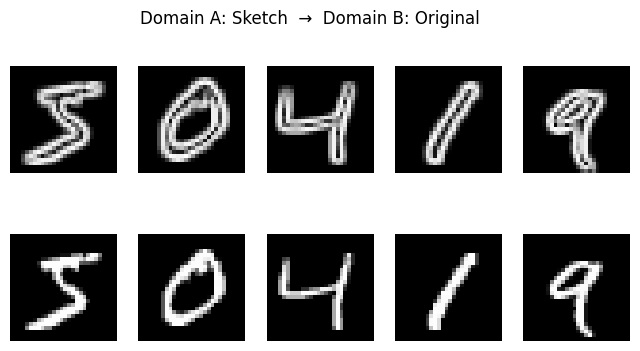

In [4]:
plt.figure(figsize=(8, 4))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow((train_sketch[i].numpy().squeeze() + 1) / 2, cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Sketch")

    plt.subplot(2, 5, i + 6)
    plt.imshow((x_train[i].squeeze() + 1) / 2, cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

plt.suptitle("Domain A: Sketch  →  Domain B: Original")
plt.show()

## Step 5: Build the Generator

The generator receives a sketch and tries to reconstruct the original digit.

In [5]:
def build_generator():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),

        tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),

        tf.keras.layers.UpSampling2D(),
        tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),

        tf.keras.layers.Conv2D(1, 3, padding="same", activation="tanh")
    ])

generator = build_generator()
generator.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 1)      │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 148,865 (581.50 KB)

 Trainable params: 148,865 (581.50 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6: Build the Discriminator

The discriminator receives the sketch together with either the real image or the generated image.

In [6]:
def build_discriminator():
    sketch_input = tf.keras.layers.Input(shape=(28, 28, 1))
    image_input = tf.keras.layers.Input(shape=(28, 28, 1))

    x = tf.keras.layers.Concatenate()([sketch_input, image_input])

    x = tf.keras.layers.Conv2D(64, 4, strides=2, padding="same")(x)
    x = tf.keras.layers.LeakyReLU(0.2)(x)

    x = tf.keras.layers.Conv2D(128, 4, strides=2, padding="same")(x)
    x = tf.keras.layers.LeakyReLU(0.2)(x)

    x = tf.keras.layers.Flatten()(x)
    output = tf.keras.layers.Dense(1)(x)

    return tf.keras.Model([sketch_input, image_input], output)

discriminator = build_discriminator()
discriminator.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 28, 28, 2) │          0 │ input_layer_1[0]… │
│ (Concatenate)       │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 14, 14,    │      2,112 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 14, 14,    │          0 │ conv2d_4[0][0]    │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 7, 7, 128) │    131,200 │ leaky_re_lu[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 7, 7, 128) │          0 │ conv2d_5[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 6272)      │          0 │ leaky_re_lu_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │      6,273 │ flatten[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 139,585 (545.25 KB)

 Trainable params: 139,585 (545.25 KB)

 Non-trainable params: 0 (0.00 B)

## Step 7: Define Loss Functions

In [7]:
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = bce(tf.ones_like(real_output), real_output)
    fake_loss = bce(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output, generated_image, target_image):
    # Adversarial loss
    gan_loss = bce(tf.ones_like(fake_output), fake_output)

    # Reconstruction loss
    l1_loss = tf.reduce_mean(tf.abs(target_image - generated_image))

    # Total generator loss
    total_loss = gan_loss + 100 * l1_loss
    return total_loss

## Step 8: Create Optimizers and Dataset

In [8]:
generator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

BATCH_SIZE = 64

train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_sketch, x_train)
).shuffle(5000).batch(BATCH_SIZE)

print("Dataset ready!")

Dataset ready!


## Step 9: Define One Training Step

In [9]:
@tf.function
def train_step(sketch, target):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        generated = generator(sketch, training=True)

        real_output = discriminator([sketch, target], training=True)
        fake_output = discriminator([sketch, generated], training=True)

        gen_loss = generator_loss(fake_output, generated, target)
        disc_loss = discriminator_loss(real_output, fake_output)

    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss

## Step 10: Train the GAN

For a quick practical demonstration, use **5 epochs**. You may increase the value for better results.

In [13]:
EPOCHS = 50

gen_history = []
disc_history = []

for epoch in range(EPOCHS):
    total_gen = 0
    total_disc = 0
    batches = 0

    for sketch_batch, target_batch in train_dataset:
        gen_loss, disc_loss = train_step(sketch_batch, target_batch)

        total_gen += float(gen_loss)
        total_disc += float(disc_loss)
        batches += 1

    avg_gen = total_gen / batches
    avg_disc = total_disc / batches

    gen_history.append(avg_gen)
    disc_history.append(avg_disc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} - "
        f"Generator Loss: {avg_gen:.4f} - "
        f"Discriminator Loss: {avg_disc:.4f}"
    )

Epoch 1/50 - Generator Loss: 6.1443 - Discriminator Loss: 1.2665
Epoch 2/50 - Generator Loss: 5.8406 - Discriminator Loss: 1.2689
Epoch 3/50 - Generator Loss: 5.6683 - Discriminator Loss: 1.2723
Epoch 4/50 - Generator Loss: 5.4440 - Discriminator Loss: 1.2649
Epoch 5/50 - Generator Loss: 5.2559 - Discriminator Loss: 1.2675
Epoch 6/50 - Generator Loss: 5.0825 - Discriminator Loss: 1.2697
Epoch 7/50 - Generator Loss: 5.0072 - Discriminator Loss: 1.2712
Epoch 8/50 - Generator Loss: 4.8713 - Discriminator Loss: 1.2755
Epoch 9/50 - Generator Loss: 4.7221 - Discriminator Loss: 1.2733
Epoch 10/50 - Generator Loss: 4.6580 - Discriminator Loss: 1.2737
Epoch 11/50 - Generator Loss: 4.5462 - Discriminator Loss: 1.2781
Epoch 12/50 - Generator Loss: 4.4419 - Discriminator Loss: 1.2840
Epoch 13/50 - Generator Loss: 4.3652 - Discriminator Loss: 1.2835
Epoch 14/50 - Generator Loss: 4.2991 - Discriminator Loss: 1.2869
Epoch 15/50 - Generator Loss: 4.2250 - Discriminator Loss: 1.2906
Epoch 16/50 - Gener

## Step 11: Plot the Training Loss

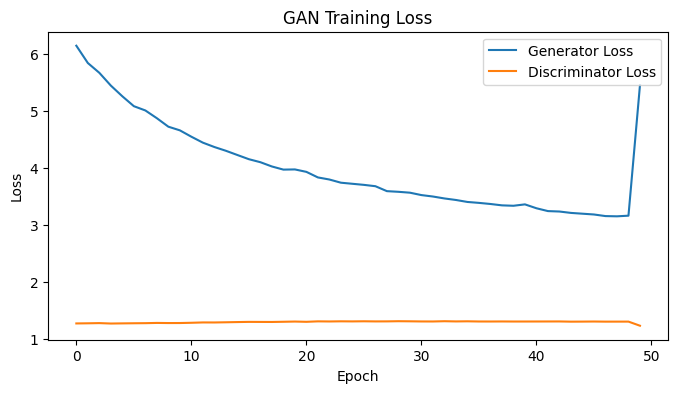

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(gen_history, label="Generator Loss")
plt.plot(disc_history, label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.show()

## Step 12: Test the Image Translation

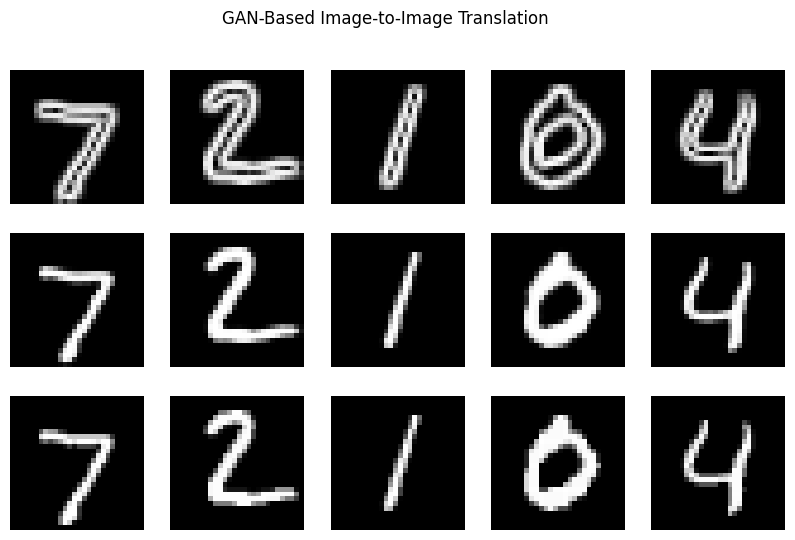

In [15]:
sample_sketch = test_sketch[:5]
sample_target = x_test[:5]

generated = generator(sample_sketch, training=False)

plt.figure(figsize=(10, 6))

for i in range(5):
    # Input sketch
    plt.subplot(3, 5, i + 1)
    plt.imshow((sample_sketch[i].numpy().squeeze() + 1) / 2, cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Sketch")

    # Generated image
    plt.subplot(3, 5, i + 6)
    plt.imshow((generated[i].numpy().squeeze() + 1) / 2, cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Generated")

    # Real target
    plt.subplot(3, 5, i + 11)
    plt.imshow((sample_target[i].squeeze() + 1) / 2, cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

plt.suptitle("GAN-Based Image-to-Image Translation")
plt.show()

# Result

The model learns to translate **edge/sketch images** into images that resemble the original handwritten digits.

This demonstrates the basic idea of **GAN-based image-to-image translation**.

# Conclusion

In this experiment, we developed a simple **conditional GAN**.

- The **Generator** translated a sketch image into an output image.
- The **Discriminator** checked whether the image was real or generated.
- The **L1 loss** helped the generated image remain similar to the correct target.

The same idea can be extended to:
- sketch → realistic image
- day → night
- black-and-white → color
- satellite image → map


## Viva Questions

1. What is a GAN?
2. What are the two main components of a GAN?
3. What is image-to-image translation?
4. What is the role of the generator?
5. What is the role of the discriminator?
6. What is a conditional GAN?
7. Why is L1 loss used?
8. Give two applications of image-to-image translation.
9. What is the difference between a real and fake pair?
10. How is this idea related to Pix2Pix?
